# Učinkovitost

## Delne vsote na več načinov

In [2]:
def delne_vsote_z_indeksi(seznam):
    vsote = []
    for i in range(len(seznam)):
        vsota = 0
        for j in range(i + 1):
            vsota += seznam[j]
        vsote.append(vsota)
    return vsote

In [3]:
def delne_vsote_z_rezinami(seznam):
    vsote = []
    for i in range(len(seznam)):
        vsota = 0
        for x in seznam[:i + 1]:
            vsota += x
        vsote.append(vsota)
    return vsote

In [4]:
def delne_vsote_s_sum(seznam):
    vsote = []
    for i in range(len(seznam)):
        vsote.append(sum(seznam[:i + 1]))
    return vsote

In [1]:
seznam = [3, 1, 4, 1, 5, 9, 2, 6]

In [5]:
delne_vsote_z_indeksi(seznam)

[3, 4, 8, 9, 14, 23, 25, 31]

In [6]:
delne_vsote_z_rezinami(seznam)

[3, 4, 8, 9, 14, 23, 25, 31]

In [7]:
delne_vsote_s_sum(seznam)

[3, 4, 8, 9, 14, 23, 25, 31]

`merjenje.py`

In [9]:
import random
import time

import matplotlib.pyplot as plt


def nakljucen_seznam(dolzina):
    return [random.randint(0, 10 * dolzina) for _ in range(dolzina)]


def nakljucen_narascajoc_seznam(dolzina):
    return sorted(nakljucen_seznam(dolzina))


def izmeri(f, seznam):
    klici = 0
    zacetek = time.perf_counter()
    konec = zacetek
    while konec - zacetek < 0.02:
        f(seznam)
        klici += 1
        konec = time.perf_counter()
    return (konec - zacetek) / klici


def izpisi_case(ime, velikosti, casi):
    print(ime)
    print(f'{velikosti[0]:>10}{casi[0]:12.2e} s')
    for i in range(1, len(velikosti)):
        razmerje = casi[i] / casi[i - 1]
        print(f'{velikosti[i]:>10}{casi[i]:12.2e} s{razmerje:8.1f}')


def narisi_case(imena, velikosti, vsi_casi):
    for ime, casi in zip(imena, vsi_casi):
        plt.plot(velikosti, casi, 'o-', label=ime)
    plt.xlabel('dolžina seznama')
    plt.ylabel('čas [s]')
    plt.legend()
    plt.show()


def primerjaj(funkcije, velikosti, naredi_seznam=nakljucen_seznam):
    imena = [f.__name__ for f in funkcije]
    vsi_casi = []
    for f in funkcije:
        casi = [izmeri(f, naredi_seznam(n)) for n in velikosti]
        izpisi_case(f.__name__, velikosti, casi)
        vsi_casi.append(casi)
    narisi_case(imena, velikosti, vsi_casi)

delne_vsote_z_indeksi
       500    2.65e-03 s
      1000    7.50e-03 s     2.8
      2000    2.75e-02 s     3.7
      4000    1.05e-01 s     3.8
delne_vsote_s_sum
       500    3.72e-04 s
      1000    1.61e-03 s     4.3
      2000    5.79e-03 s     3.6
      4000    2.36e-02 s     4.1
delne_vsote_z_rezinami
       500    1.21e-03 s
      1000    4.66e-03 s     3.9
      2000    1.85e-02 s     4.0
      4000    7.53e-02 s     4.1


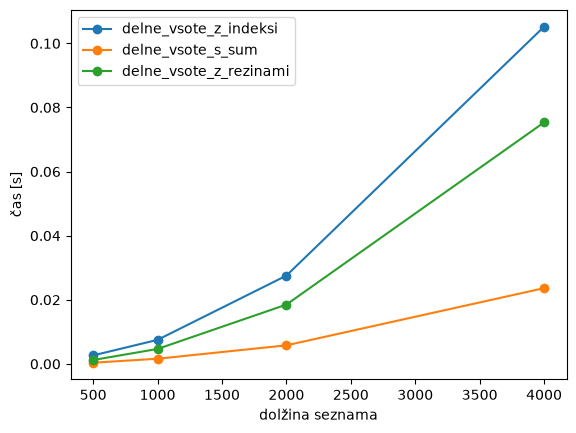

In [10]:
primerjaj([delne_vsote_z_indeksi, delne_vsote_s_sum, delne_vsote_z_rezinami], [500, 1000, 2000, 4000])

In [11]:
def delne_vsote_sproti(seznam):
    vsote = []
    vsota = 0
    for x in seznam:
        vsota += x
        vsote.append(vsota)
    return vsote

In [12]:
delne_vsote_sproti(seznam)

[3, 4, 8, 9, 14, 23, 25, 31]

delne_vsote_sproti
       500    1.50e-05 s
      1000    2.23e-05 s     1.5
      1500    2.86e-05 s     1.3
      2000    3.52e-05 s     1.2
      2500    4.25e-05 s     1.2
      3000    5.10e-05 s     1.2
      3500    6.05e-05 s     1.2
      4000    6.63e-05 s     1.1
      4500    7.50e-05 s     1.1
      5000    8.27e-05 s     1.1
      5500    9.11e-05 s     1.1
      6000    9.97e-05 s     1.1
      6500    1.06e-04 s     1.1
      7000    1.15e-04 s     1.1
      7500    1.28e-04 s     1.1
      8000    1.34e-04 s     1.0
      8500    1.42e-04 s     1.1
      9000    1.49e-04 s     1.0
      9500    1.59e-04 s     1.1
     10000    1.61e-04 s     1.0


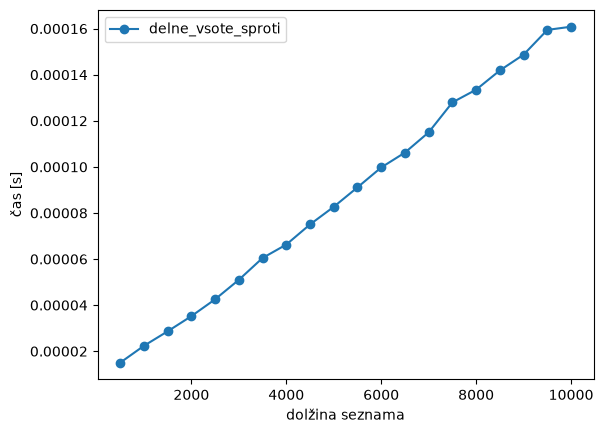

In [19]:
primerjaj([delne_vsote_sproti], range(500, 10001, 500))

## Kaj merimo?

## Kako merimo?

## Zahtevnosti znanih operacij

In [32]:
def dodaj_na_konec(seznam):
    nov = []
    for x in seznam:
        nov.append(x)
    return nov

In [33]:
def dodaj_na_zacetek(seznam):
    nov = []
    for x in seznam:
        nov.insert(0, x)
    return nov

dodaj_na_konec
      5000    6.27e-05 s
     10000    9.00e-05 s     1.4
     20000    1.51e-04 s     1.7
     40000    2.60e-04 s     1.7
dodaj_na_zacetek
      5000    3.39e-03 s
     10000    1.32e-02 s     3.9
     20000    5.33e-02 s     4.0
     40000    2.21e-01 s     4.1


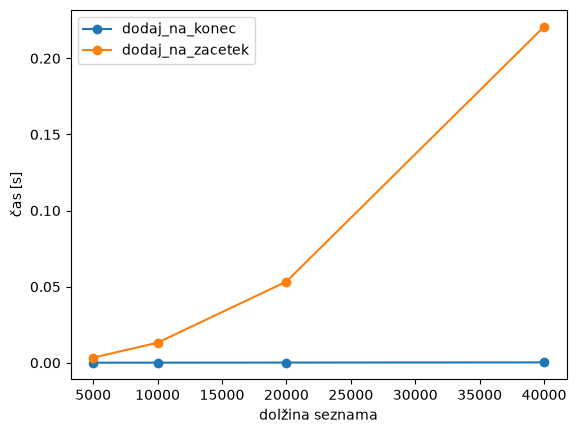

In [34]:
primerjaj([dodaj_na_konec, dodaj_na_zacetek], [5000, 10000, 20000, 40000])

<div class="diagram" ondblclick="event.stopPropagation()">
<div class="diagram-step"></div>
<div class="diagram-step" hidden></div>
<div class="diagram-step" hidden></div>
<div class="diagram-step" hidden></div>
<div class="diagram-nav"><button type="button" data-d="-1" aria-label="nazaj" onclick="var f = this.closest('.diagram'), s = f.querySelectorAll('.diagram-step'), i = f.querySelector('.diagram-index'), k = i.textContent - 1; s[k].hidden = true; k = (k + s.length + Number(this.dataset.d)) % s.length; s[k].hidden = false; i.textContent = k + 1">&lsaquo;</button> <span class="diagram-index">1</span>/4 <button type="button" data-d="1" aria-label="naprej" onclick="var f = this.closest('.diagram'), s = f.querySelectorAll('.diagram-step'), i = f.querySelector('.diagram-index'), k = i.textContent - 1; s[k].hidden = true; k = (k + s.length + Number(this.dataset.d)) % s.length; s[k].hidden = false; i.textContent = k + 1">&rsaquo;</button></div>
</div>

len
         1    5.49e-08 s
         1    4.59e-08 s     0.8
         1    4.19e-08 s     0.9
         1    4.18e-08 s     1.0
         1    4.22e-08 s     1.0
         1    4.20e-08 s     1.0
         1    4.13e-08 s     1.0
         1    4.10e-08 s     1.0
         1    4.09e-08 s     1.0
         1    4.08e-08 s     1.0
         1    4.17e-08 s     1.0
         1    4.11e-08 s     1.0
         1    4.12e-08 s     1.0
         1    4.19e-08 s     1.0
         1    4.16e-08 s     1.0
         1    4.15e-08 s     1.0
         1    4.22e-08 s     1.0
         1    4.13e-08 s     1.0
         1    4.14e-08 s     1.0
         1    4.26e-08 s     1.0
         1    4.22e-08 s     1.0
         1    4.21e-08 s     1.0
         1    4.18e-08 s     1.0
         1    4.26e-08 s     1.0
         1    4.10e-08 s     1.0
         1    4.16e-08 s     1.0
         1    4.24e-08 s     1.0
         1    4.13e-08 s     1.0
         1    4.12e-08 s     1.0
         1    4.26e-08 s     1.0
         1    

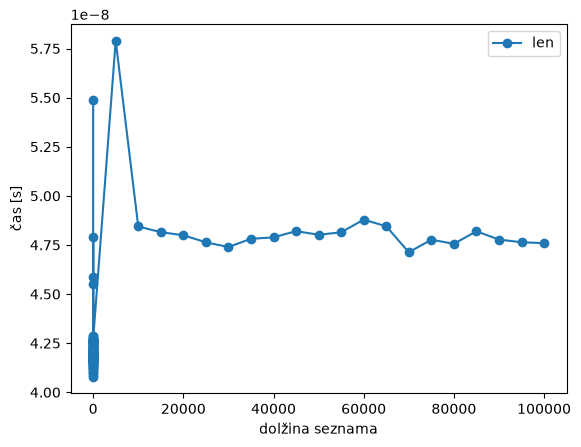

In [31]:
primerjaj([len], 100 * [1] + list(range(5000, 100001, 5000)))

sum
     10000    2.90e-05 s
     20000    5.06e-05 s     1.7
     40000    9.33e-05 s     1.8
     80000    1.71e-04 s     1.8


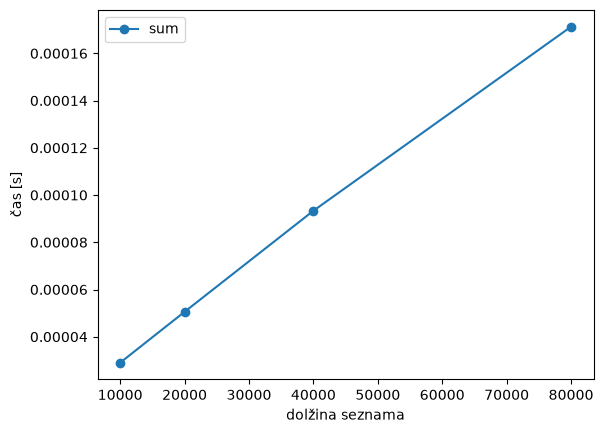

In [21]:
primerjaj([sum], [10000, 20000, 40000, 80000])

min
     10000    9.45e-05 s
     20000    1.50e-04 s     1.6
     40000    2.72e-04 s     1.8
     80000    5.22e-04 s     1.9


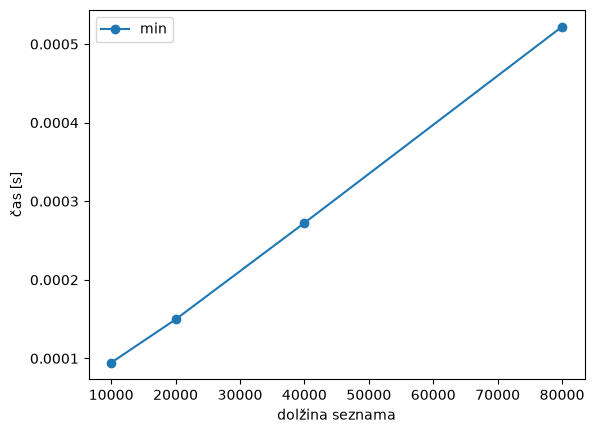

In [24]:
primerjaj([min], [10000, 20000, 40000, 80000])

In [35]:
def srednji_element(seznam):
    return seznam[len(seznam) // 2]

srednji_element
     10000    1.44e-07 s
     20000    9.88e-08 s     0.7
     40000    8.00e-08 s     0.8
     80000    6.58e-08 s     0.8


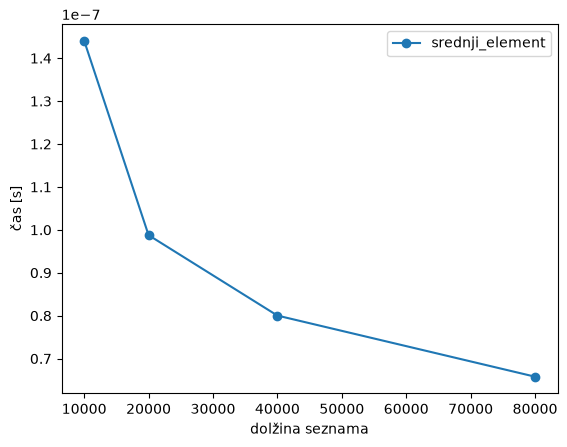

In [36]:
primerjaj([srednji_element], [10000, 20000, 40000, 80000])

In [ ]:
def prva_polovica(seznam):
    return seznam[:len(seznam) // 2]

In [ ]:
primerjaj([prva_polovica], [10000, 20000, 40000, 80000])

In [ ]:
def poisci_manjkajoci(seznam):
    return -1 in seznam

In [ ]:
primerjaj([poisci_manjkajoci], [10000, 20000, 40000, 80000])

## Iskanje

In [37]:
def ali_vsebuje(sez, x):
    for y in sez:
        if y == x:
            return True
    return False

In [ ]:
def nakljucen_narascajoc_seznam(dolzina):
    return sorted(nakljucen_seznam(dolzina))

In [40]:
def ali_vsebuje_urejen(sez, x):
    od = 0
    do = len(sez) - 1
    while od <= do:
        sredina = (od + do) // 2
        if sez[sredina] == x:
            return True
        elif sez[sredina] < x:
            od = sredina + 1
        else:
            do = sredina - 1
    return False

In [38]:
def isci_linearno(sez):
    return ali_vsebuje(sez, -1)

In [41]:
def isci_z_bisekcijo(sez):
    return ali_vsebuje_urejen(sez, -1)

isci_linearno
     10000    7.62e-05 s
     20000    1.18e-04 s     1.5
     40000    2.19e-04 s     1.9
     80000    4.58e-04 s     2.1
isci_z_bisekcijo
     10000    5.44e-07 s
     20000    5.49e-07 s     1.0
     40000    5.99e-07 s     1.1
     80000    6.21e-07 s     1.0


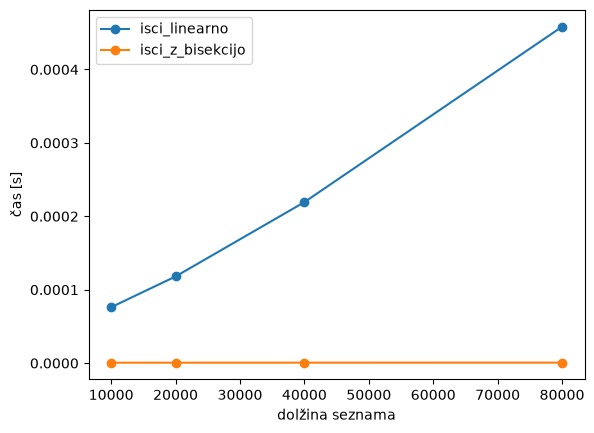

In [42]:
primerjaj([isci_linearno, isci_z_bisekcijo], [10000, 20000, 40000, 80000], nakljucen_narascajoc_seznam)

In [ ]:
import math

In [ ]:
math.log2(4 * 10 ** 9)

In [ ]:
stiri_milijarde = range(4 * 10 ** 9)

In [ ]:
ali_vsebuje_urejen(stiri_milijarde, 3141592653)

In [ ]:
def vstavi_urejeno(sez, x):
    sez.append(x)
    i = len(sez) - 1
    while i > 0 and sez[i - 1] > sez[i]:
        sez[i - 1], sez[i] = sez[i], sez[i - 1]
        i -= 1

In [ ]:
def uredi_z_vstavljanjem(seznam):
    urejen = []
    for x in seznam:
        vstavi_urejeno(urejen, x)
    return urejen

In [ ]:
uredi_z_vstavljanjem(seznam)

In [ ]:
primerjaj([uredi_z_vstavljanjem], [500, 1000, 2000, 4000])